In [57]:
%pylab inline

import gc
import os
import pltutil
import catutil
import smatch
import treecorr
import numpy as np
import astropy.table as astTab
import astropy.io.fits as pyfits
import matplotlib.pylab as plt
import matplotlib.lines as mlines

datDir='wrkDir/s19/s19-pre/psf_test_from_wentao/rhoTest/'
pltDir='wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/psfTest/'

def get_rho_data(cat):
    sstar=catutil.get_sdss_size(cat,'trace')**2.
    spsf= catutil.get_psf_size(cat,'trace')**2.
    fdt = -(spsf-sstar)/sstar
        
    g1Star,g2Star=catutil.get_sdss_ellip(cat,return_shear=True)
    g1PSF,g2PSF=catutil.get_psf_ellip(cat,return_shear=True)
    dg1=   g1Star-g1PSF
    dg2=   g2Star-g2PSF
    ra,dec=catutil.get_radec(cat)
    types=[('ra','>f8'),('dec','>f8'),('g1p','>f8'),\
           ('g2p','>f8'),('dg1','>f8'),('dg2','>f8'),\
           ('fdt','>f8')]
    out=np.empty(len(ra),dtype=types)
    out['ra']=ra
    out['dec']=dec
    out['g1p']=g1PSF
    out['g2p']=g2PSF
    out['dg1']=dg1
    out['dg2']=dg2
    out['fdt']=fdt
    return out

def get_GG(ra,dec,g1,g2,g1B=None,g2B=None,weights=None):
    cor  =   treecorr.GGCorrelation(nbins=20,min_sep=0.05,max_sep=1.7,sep_units='degree')
    catT1=   treecorr.Catalog(g1=g1,g2=-g2,\
                                ra=ra,dec=dec,\
                                ra_units='deg',dec_units='deg',w=weights) 
    if g1B is None:
        cor.process(catT1,catT1)
    else:
        catTB=   treecorr.Catalog(g1=g1B,g2=-g2B,\
                    ra=ra,dec=dec,\
                    ra_units='deg',dec_units='deg',w=weights) 
        cor.process(catT1,catTB)

    return cor

def get_meanRho(rhoTmp,weights=None,ver='rho1'):
    if ver=='rho1':
        corTmp=get_GG(rhoTmp['ra'],rhoTmp['dec'],rhoTmp['dg1'],rhoTmp['dg2'],\
                  weights=weights)
    elif ver=='rho2':
        corTmp=get_GG(rhoTmp['ra'],rhoTmp['dec'],rhoTmp['g1p'],rhoTmp['g2p'],\
                  rhoTmp['dg1'],rhoTmp['dg2'],weights=weights)
    elif ver=='rho3':
        corTmp=get_GG(rhoTmp['ra'],rhoTmp['dec'],rhoTmp['g1p']*rhoTmp['fdt'],\
                  rhoTmp['g2p']*rhoTmp['fdt'],weights=weights)
    elif ver=='rho4':
        corTmp=get_GG(rhoTmp['ra'],rhoTmp['dec'],rhoTmp['g1p']*rhoTmp['fdt'],\
                  rhoTmp['g2p']*rhoTmp['fdt'],rhoTmp['dg1'],rhoTmp['dg2'],\
                  weights=weights)
    elif ver=='rho5':
        corTmp=get_GG(rhoTmp['ra'],rhoTmp['dec'],rhoTmp['g1p']*rhoTmp['fdt'],\
                  rhoTmp['g2p']*rhoTmp['fdt'],rhoTmp['g1p'],rhoTmp['g2p'],\
                  weights=weights)
    return corTmp

def get_stdRho(rho,ver='rho1'):
    nstar=len(rho)
    xipAll=[]
    for i in range(40):
        np.random.seed(i)
        indTmp=np.random.randint(0,nstar,size=nstar)
        rhoTmp=rho[indTmp]
        corTmp=get_meanRho(rhoTmp,ver=ver)
        xipAll.append(corTmp.xip)
        del indTmp,corTmp,rhoTmp
        gc.collect()
    xipAll=np.vstack(xipAll)
    return np.std(xipAll,axis=0)
    
def make_plot(ax,meanr,xip,xierr,cc='black'):
    msk=xip>0
    xrr=meanr[msk]*60.
    xxp=xip[msk]
    xxv=xierr[msk]
    ax.errorbar(xrr,xxp,xxv,fmt='x',alpha=0.85,\
                color=cc,ms=6,elinewidth=1.5,capsize=0,capthick=0.,linewidth=1.)
    nnn=np.sum(msk)
    if nnn<20:
        xrr=meanr[~msk]*60.
        xxp=xip[~msk]
        xxv=xierr[~msk]
        ax.errorbar(xrr,-xxp,xxv,fmt='s',alpha=0.85,\
                    color=cc,ms=6,elinewidth=1.5,capsize=0,capthick=0.,linewidth=1.)

    return

Populating the interactive namespace from numpy and matplotlib


In [2]:
# With FDFC cut
pend='fdcut'
allname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_sm-S19A-g15_star.fits'
elinpname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_sm-S19A-g15_nonpsfstars.fits'
cat1=pyfits.getdata(allname)
cat2=pyfits.getdata(elinpname)
hpfname =   "s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"
hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
maskP1=catutil.get_FDFC_flag(cat1,hpfname=hpfname)
maskP2=catutil.get_FDFC_flag(cat2,hpfname=hpfname)

cat3=cat1[~cat1['i_calib_psf_used']&maskP1]
cat1=cat1[cat1['i_calib_psf_used']&maskP1]
cat2=cat2[maskP2]

NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


In [3]:
w2=None
plt.close()
fig=plt.figure(figsize=(12,6))
ax=fig.add_subplot(1,2,1)
hist1,bb,_xx=ax.hist(cat1['i_psfflux_mag'],label='PSF Stars',density=True,range=(17.5,22.5),bins=15,histtype='step')
ax.hist(cat3['i_psfflux_mag'],label='non-PSF Stars',density=True,range=(17.5,22.5),bins=15,histtype='step')
hist2,bb,_xx=ax.hist(cat2['i_psfflux_mag'],label='FGCM non-PSF Stars',density=True,range=(17.5,22.5),bins=15,histtype='step',weights=w2)
w2_tmp=hist1/hist2
w2=w2_tmp[np.digitize(cat2['i_psfflux_mag'],bins=bb)-1]

ax.legend(loc='upper left')
ax.set_xlabel(r'$i$-band PSF magnitude')
ax=fig.add_subplot(1,2,2)
ax.hist(catutil.get_psf_size(cat1),label='PSF Stars',density=True,histtype='step')
ax.hist(catutil.get_psf_size(cat3),label='non-PSF Stars',density=True,histtype='step')
ax.hist(catutil.get_psf_size(cat2),label='FGCM non-PSF Stars',density=True,histtype='step')
ax.set_xlabel('FWHM [arcsec]')

Text(0.5, 0, 'FWHM [arcsec]')

In [4]:
rhoA=get_rho_data(cat1)
rhoB=get_rho_data(cat2)

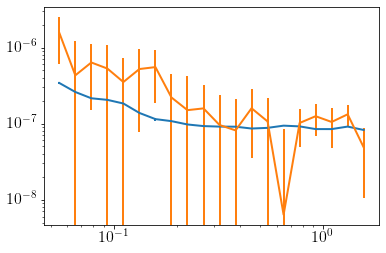

In [102]:
# rho1
corB=get_GG(rhoB['ra'],rhoB['dec'],rhoB['dg1'],rhoB['dg2'],weights=w2)
stdB=get_stdRho(rhoB,'rho1')
corA=get_GG(rhoA['ra'],rhoA['dec'],rhoA['dg1'],rhoA['dg2'],weights=None)
stdA=get_stdRho(rhoA,'rho1')
tab1=astTab.Table(data=[corA.meanr,corA.xip,stdA,corB.xip,stdB],\
                  names=['meanr','xipA','stdA','xipB','stdB'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipA']),tab1['stdA'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipB']),tab1['stdB'])
plt.xscale('log')
plt.yscale('log')
tab1.write(os.path.join(pltDir,'psf_rho1_tests_%s_reweight.csv' %pend))

In [ ]:
# rho2
del corA,corB,stdA,stdB,tab1
gc.collect()
corA=get_GG(rhoA['ra'],rhoA['dec'],rhoA['g1p'],rhoA['g2p'],rhoA['dg1'],rhoA['dg2'],weights=None)
stdA=get_stdRho(rhoA,'rho2')
corB=get_GG(rhoB['ra'],rhoB['dec'],rhoB['g1p'],rhoB['g2p'],rhoB['dg1'],rhoB['dg2'],weights=None)
stdB=get_stdRho(rhoB,'rho2')
tab1=astTab.Table(data=[corA.meanr,corA.xip,stdA,corB.xip,stdB],names=['meanr','xipA','stdA','xipB','stdB'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipA']),tab1['stdA'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipB']),tab1['stdB'])
plt.xscale('log')
plt.yscale('log')
tab1.write(os.path.join(pltDir,'psf_rho2_tests_%s_reweight.csv' %pend))

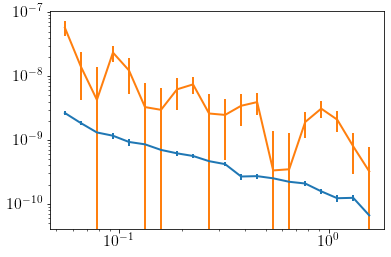

In [120]:
# rho3
del corA,corB,stdA,stdB,tab1
gc.collect()
corA=get_GG(rhoA['ra'],rhoA['dec'],rhoA['g1p']*rhoA['fdt'],rhoA['g2p']*rhoA['fdt'],weights=None)
stdA=get_stdRho(rhoA,'rho3')
corB=get_GG(rhoB['ra'],rhoB['dec'],rhoB['g1p']*rhoB['fdt'],rhoB['g2p']*rhoB['fdt'],weights=w2)
stdB=get_stdRho(rhoB,'rho3')
tab1=astTab.Table(data=[corA.meanr,corA.xip,stdA,corB.xip,stdB],names=['meanr','xipA','stdA','xipB','stdB'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipA']),tab1['stdA'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipB']),tab1['stdB'])
plt.xscale('log')
plt.yscale('log')
tab1.write(os.path.join(pltDir,'psf_rho3_tests_%s_reweight.csv' %pend))

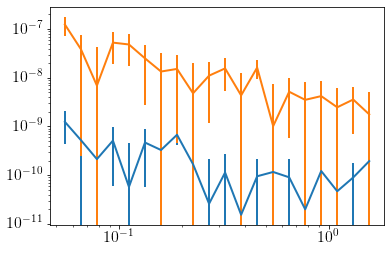

In [12]:
# rho4
del corA,corB,stdA,stdB,tab1
gc.collect()
corA=get_GG(rhoA['ra'],rhoA['dec'],rhoA['g1p']*rhoA['fdt'],rhoA['g2p']*rhoA['fdt'],\
            rhoA['dg1'],rhoA['dg2'],weights=None)
stdA=get_stdRho(rhoA,'rho4')
corB=get_GG(rhoB['ra'],rhoB['dec'],rhoB['g1p']*rhoB['fdt'],rhoB['g2p']*rhoB['fdt'],\
            rhoB['dg1'],rhoB['dg2'],weights=w2)
stdB=get_stdRho(rhoB,'rho4')
tab1=astTab.Table(data=[corA.meanr,corA.xip,stdA,corB.xip,stdB],names=['meanr','xipA','stdA','xipB','stdB'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipA']),tab1['stdA'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipB']),tab1['stdB'])
plt.xscale('log')
plt.yscale('log')
tab1.write(os.path.join(pltDir,'psf_rho4_tests_%s_reweight.csv' %pend))

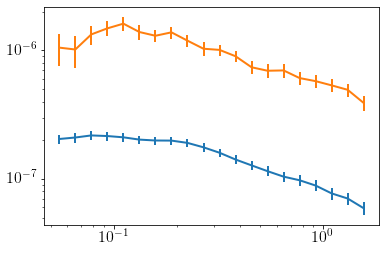

In [16]:
# rho5
del corA,corB,stdA,stdB,tab1
gc.collect()
corA=get_GG(rhoA['ra'],rhoA['dec'],rhoA['g1p']*rhoA['fdt'],rhoA['g2p']*rhoA['fdt'],\
            rhoA['g1p'],rhoA['g2p'],weights=None)
stdA=get_stdRho(rhoA,'rho5')
corB=get_GG(rhoB['ra'],rhoB['dec'],rhoB['g1p']*rhoB['fdt'],rhoB['g2p']*rhoB['fdt'],\
            rhoB['g1p'],rhoB['g2p'],weights=w2)
stdB=get_stdRho(rhoB,'rho5')
tab1=astTab.Table(data=[corA.meanr,corA.xip,stdA,corB.xip,stdB],names=['meanr','xipA','stdA','xipB','stdB'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipA']),tab1['stdA'])
plt.errorbar(tab1['meanr'], np.abs(tab1['xipB']),tab1['stdB'])
plt.xscale('log')
plt.yscale('log')
tab1.write(os.path.join(pltDir,'psf_rho5_tests_%s_reweight.csv' %pend))

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:101: MatplotlibDeprecationWarning: savefig() got unexpected keyword argument "rasterized" which is no longer supported as of 3.3 and will become an error two minor releases later


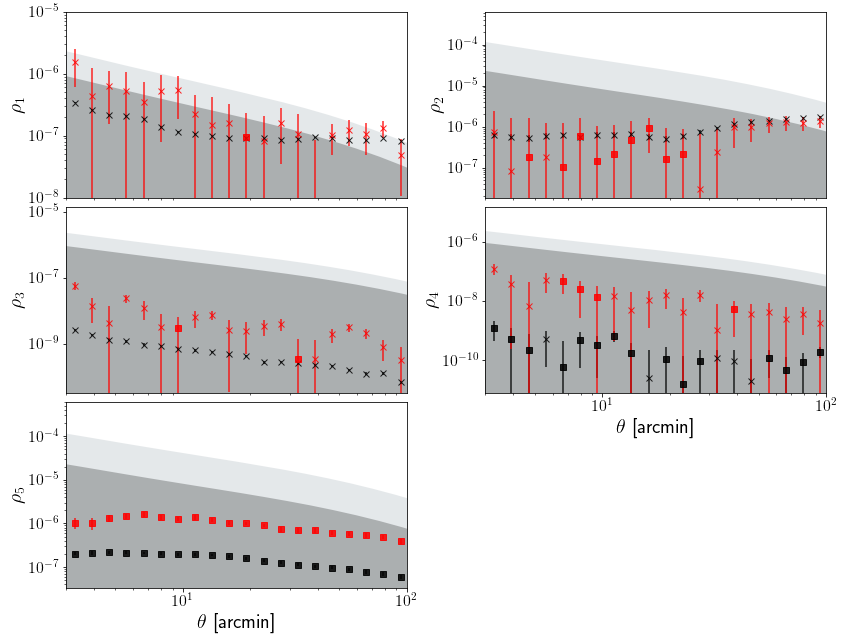

In [49]:
plt.close()

fc2='#747778'
fc1='#cbd2d6'
req=astTab.Table.read(os.path.join(datDir,'rho_requirements.csv'))
rrn=req['rr'];rho134n=req['rho134'];rho25n=req['rho25']
# requirement
rr,rho134,rho25=np.loadtxt(os.path.join(datDir,'rho_requirements.txt'),unpack=True,comments='#')
req=astTab.Table.read(os.path.join(datDir,'rho_requirements.csv'))
rrn=req['rr'];rho134n=req['rho134'];rho25n=req['rho25']
rr=rr*60
rrn=rrn*60

fig=plt.figure(figsize=(12,10))
fig.set_rasterized(True) 

# rho1
ax=fig.add_subplot(3,2,1)
ax.fill_between(rr,rho134,-rho134,facecolor=fc1,linewidth=0.0,zorder=2,alpha=0.5)
ax.fill_between(rrn,rho134n,-rho134n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)
data=astTab.Table.read(os.path.join(pltDir,'psf_rho1_tests_%s_reweight.csv' %pend))
make_plot(ax,data['meanr'],data['xipA'],data['stdA'],'black')
make_plot(ax,data['meanr'],data['xipB'],data['stdB'],'red')

ax.set_xscale('log')
ax.set_xlim(0.05*60,100.)
ax.set_xticks(())
ax.set_yscale('log')
ax.set_ylabel(r"$\rho_1$",fontsize=20.0)
ax.set_ylim(1e-8,1e-5)
ax.set_rasterized(True)


ax=fig.add_subplot(3,2,2)
ax.fill_between(rr,rho25,-rho25,facecolor=fc1,linewidth=0.0,zorder=1,alpha=0.5)
ax.fill_between(rrn,rho25n,-rho25n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)

data=astTab.Table.read(os.path.join(pltDir,'psf_rho2_tests_%s_reweight.csv' %pend))
make_plot(ax,data['meanr'],data['xipA'],data['stdA'],'black')
make_plot(ax,data['meanr'],data['xipB'],data['stdB'],'red')

ax.set_xlim(0.05*60,100.)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks(())
ax.set_xticklabels(())
ax.set_ylabel(r"$\rho_2$",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,3)
ax.fill_between(rr,rho134,-rho134,facecolor=fc1,linewidth=0.0,zorder=1,alpha=0.5)
ax.fill_between(rrn,rho134n,-rho134n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)

data=astTab.Table.read(os.path.join(pltDir,'psf_rho3_tests_%s_reweight.csv' %pend))
make_plot(ax,data['meanr'],data['xipA'],data['stdA'],'black')
make_plot(ax,data['meanr'],data['xipB'],data['stdB'],'red')

ax.set_xlim(0.05*60,100.)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks(())
ax.set_xticklabels(())
ax.set_ylabel(r"$\rho_3$",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,4)
ax.fill_between(rr,rho134,-rho134,facecolor=fc1,linewidth=0.0,zorder=1,alpha=0.5)
ax.fill_between(rrn,rho134n,-rho134n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)

data=astTab.Table.read(os.path.join(pltDir,'psf_rho4_tests_%s_reweight.csv' %pend))
make_plot(ax,data['meanr'],data['xipA'],data['stdA'],'black')
make_plot(ax,data['meanr'],data['xipB'],data['stdB'],'red')

ax.set_xlim(0.05*60,100.)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel(r"$\rho_4$",fontsize=20.0)
ax.set_xlabel(r"$\theta$ [arcmin]",fontsize=20.0)
ax.set_rasterized(True)

ax=fig.add_subplot(3,2,5)
ax.fill_between(rr,rho25,-rho25,facecolor=fc1,linewidth=0.0,zorder=1,alpha=0.5)
ax.fill_between(rrn,rho25n,-rho25n,facecolor=fc2,linewidth=0.0,zorder=2,alpha=0.5)

data=astTab.Table.read(os.path.join(pltDir,'psf_rho5_tests_%s_reweight.csv' %pend))
make_plot(ax,data['meanr'],data['xipA'],data['stdA'],'black')
make_plot(ax,data['meanr'],data['xipB'],data['stdB'],'red')

ax.set_xlim(0.05*60,100.)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel(r"$\rho_5$",fontsize=20.0)
ax.set_xlabel(r"$\theta$ [arcmin]",fontsize=20.0)
ax.set_rasterized(True)
fig.subplots_adjust(left=0.1,
                bottom=0.12, 
                right=0.98, 
                top=0.92, 
                wspace=0.23, 
                hspace=0.05)
fig.savefig(os.path.join(pltDir,'psf_rho_tests_%s_reweight.pdf' %pend),rasterized=True,dpi=200)
fig.savefig(os.path.join(pltDir,'psf_rho_tests_%s_reweight.png' %pend))

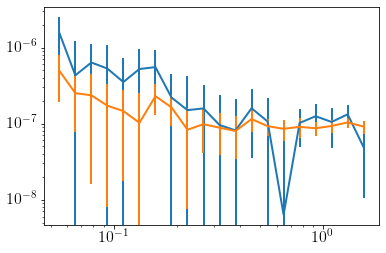

In [39]:
# rho1
corB=get_meanRho(rhoB,weights=w2,ver='rho1')
stdB=get_stdRho(rhoB,ver='rho1')

inds=np.arange(0,len(rhoA))
np.random.shuffle(inds)
rhoAB=rhoA[inds[:len(rhoB)]]

corAB=get_meanRho(rhoAB,ver='rho1')
stdAB=get_stdRho(rhoAB,ver='rho1')

plt.errorbar(corB.meanr, np.abs(corB.xip),stdB)
plt.errorbar(corAB.meanr, np.abs(corAB.xip),stdAB)
plt.xscale('log')
plt.yscale('log')

Text(0.5, 0, '$\\theta$ [arcmin]')

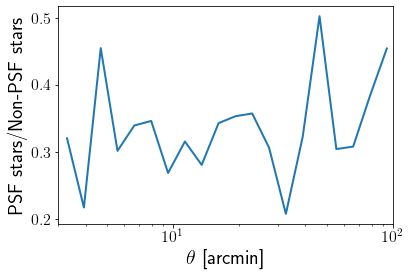

In [47]:
plt.plot(corB.meanr*60.,stdAB/stdB)
plt.xlim(0.05*60,100.)
plt.xscale('log')
plt.ylabel("PSF stars/Non-PSF stars",fontsize=20.0)
plt.xlabel(r"$\theta$ [arcmin]",fontsize=20.0)

In [64]:
def calcDistanceAngle(a1, a2, d1, d2):
    a1_f64 = np.array(a1, dtype = np.float64)
    d1_f64 = np.array(d1, dtype = np.float64)
    a2_f64 = np.array(a2, dtype = np.float64)
    d2_f64 = np.array(d2, dtype = np.float64)
    return np.arccos(np.cos(d1_f64)*np.cos(d2_f64)*np.cos(a1_f64-a2_f64)+np.sin(d1_f64)*np.sin(d2_f64))

def get_rho_each_pair(dd):
    nside=4096 # healpix nside
    maxmatch=-1 # return closest match
    radius=5/60
    cat=smatch.Catalog(dd['ra'], dd['dec'], radius, nside=nside)
    # ra,dec,radius in degrees
    cat.match_self(maxmatch=maxmatch)
    raA=dd['ra'][cat.matches['i1']]/180.*np.pi
    raB=dd['ra'][cat.matches['i2']]/180.*np.pi
    decA=dd['dec'][cat.matches['i1']]/180.*np.pi
    decB=dd['dec'][cat.matches['i2']]/180.*np.pi
    dis=calcDistanceAngle(raA,raB,decA,decB)*180./np.pi*60.

    dg1A=dd['dg1'][cat.matches['i1']]
    dg1B=dd['dg1'][cat.matches['i2']]
    dg2A=dd['dg2'][cat.matches['i1']]
    dg2B=dd['dg2'][cat.matches['i2']]
    rho1=dg1A*dg1B+dg2A*dg2B
    
    types=[('i1','>i8'),('i2','>i8'),('rho1','>f8')]
    out=np.empty(len(rho1),dtype=types)
    out['i1']=cat.matches['i1']
    out['i2']=cat.matches['i2']
    out['rho1']=rho1
    return out

In [65]:
out=get_rho_each_pair(rhoB)
inds=np.arange(0,len(rhoA))
np.random.shuffle(inds)
rhoAB=rhoA[inds[:len(rhoB)]]
out2=get_rho_each_pair(rhoAB)

1.9316689759237715e-06
6.010084739537089e-07


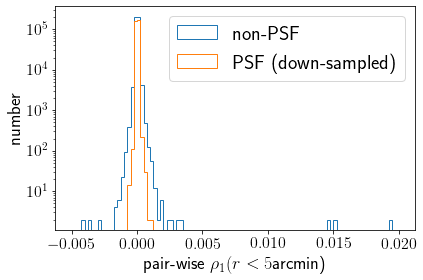

In [66]:
print(np.average(xi))
plt.hist(out['rho1'],bins=100,range=(-0.005,0.020),histtype='step',label='non-PSF')
print(np.average(xi2))
plt.hist(out2['rho1'],bins=100,range=(-0.005,0.020),histtype='step',label='PSF (down-sampled)')
plt.yscale('log')
plt.xlabel(r'pair-wise $\rho_1 (r<5$arcmin)')
plt.ylabel('number')
plt.legend()
plt.tight_layout()

In [72]:
inds=np.unique(out['i1'][np.abs(out['rho1'])>0.002])

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: divide by zero encountered in log
  """Entry point for launching an IPython kernel.


(array([14.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.]),
 array([-6.       , -5.8486032, -5.697207 , -5.5458107, -5.394414 ,
        -5.243017 , -5.091621 , -4.9402246, -4.788828 , -4.637431 ,
        -4.486035 ], dtype=float32),
 <BarContainer object of 10 artists>)

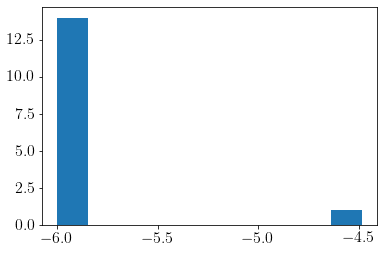

In [83]:
plt.hist()

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: divide by zero encountered in log10
  """Entry point for launching an IPython kernel.


(array([8., 0., 1., 1., 2., 1., 0., 1., 0., 1.]),
 array([-6.       , -5.594826 , -5.189652 , -4.784478 , -4.379304 ,
        -3.9741302, -3.5689561, -3.1637821, -2.7586083, -2.3534343,
        -1.9482603], dtype=float32),
 <BarContainer object of 10 artists>)

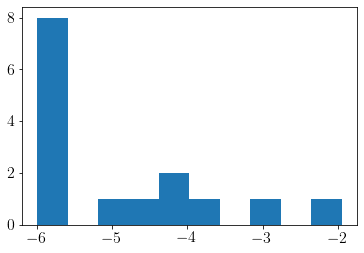

In [89]:
plt.hist(np.maximum(np.log10(cat2[inds]['i_blendedness_abs']),-6))

In [96]:
len(rhoB,np.maximum(np.log10(cat2[inds]['i_blendedness_abs']),-6))

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: divide by zero encountered in log10
  """Entry point for launching an IPython kernel.


TypeError: len() takes exactly one argument (2 given)

84434

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: divide by zero encountered in log10
  This is separate from the ipykernel package so we can avoid doing imports until
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:7: RuntimeWarning: divide by zero encountered in log10
  import sys
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:11: RuntimeWarning: divide by zero encountered in log10
  # This is added back by InteractiveShellApp.init_path()


Text(0, 0.5, '$log_{10}$(blendedness)')

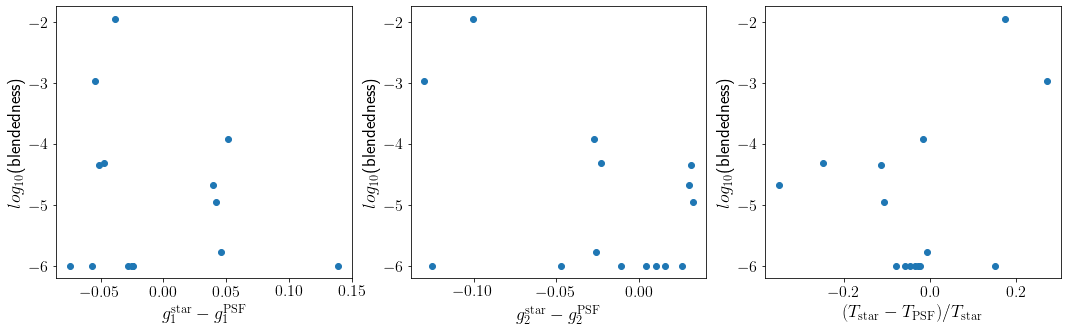

In [117]:
fig=plt.figure(figsize=(18,5))
fig.add_subplot(1,3,1)
plt.scatter(rhoB['dg1'][inds],np.maximum(np.log10(cat2[inds]['i_blendedness_abs']),-6))
plt.xlabel(r'$g^{\rm star}_1-g^{\rm PSF}_1$')
plt.ylabel(r'$log_{10}$(blendedness)')
fig.add_subplot(1,3,2)
plt.scatter(rhoB['dg2'][inds],np.maximum(np.log10(cat2[inds]['i_blendedness_abs']),-6))
plt.xlabel(r'$g^{\rm star}_2-g^{\rm PSF}_2$')
plt.ylabel(r'$log_{10}$(blendedness)')
fig.add_subplot(1,3,3)
plt.scatter(rhoB['fdt'][inds],np.maximum(np.log10(cat2[inds]['i_blendedness_abs']),-6))
plt.xlabel(r'$(T_{\rm star}-T_{\rm PSF})/T_{\rm star}$')
plt.ylabel(r'$log_{10}$(blendedness)')

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: divide by zero encountered in log10
  This is separate from the ipykernel package so we can avoid doing imports until
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:3: RuntimeWarning: invalid value encountered in log10
  This is separate from the ipykernel package so we can avoid doing imports until
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:7: RuntimeWarning: divide by zero encountered in log10
  import sys
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:7: RuntimeWarning: invalid value encountered in log10
  import sys
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:11: RuntimeWarning: divide by zero encountered in log10
  # This is

(-0.5, 0.5)

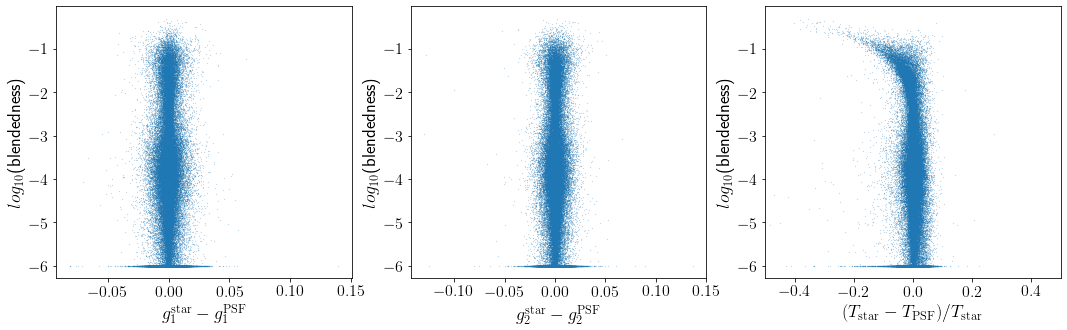

In [119]:
fig=plt.figure(figsize=(18,5))
fig.add_subplot(1,3,1)
plt.scatter(rhoB['dg1'],np.maximum(np.log10(cat2['i_blendedness_abs']),-6),s=0.01)
plt.xlabel(r'$g^{\rm star}_1-g^{\rm PSF}_1$')
plt.ylabel(r'$log_{10}$(blendedness)')
fig.add_subplot(1,3,2)
plt.scatter(rhoB['dg2'],np.maximum(np.log10(cat2['i_blendedness_abs']),-6),s=0.01)
plt.xlabel(r'$g^{\rm star}_2-g^{\rm PSF}_2$')
plt.ylabel(r'$log_{10}$(blendedness)')
fig.add_subplot(1,3,3)
plt.scatter(rhoB['fdt'],np.maximum(np.log10(cat2['i_blendedness_abs']),-6),s=0.01)
plt.xlabel(r'$(T_{\rm star}-T_{\rm PSF})/T_{\rm star}$')
plt.ylabel(r'$log_{10}$(blendedness)')
plt.xlim(-0.5,0.5)